# Regression: New York City Taxi Trip Duration

Based on individual trip attributes, the duration of the trip should be predicted.

**Data fields**

* `id` - a unique identifier for each trip
* `vendor_id` - a code indicating the provider associated with the trip record
* `pickup_datetime` - date and time when the meter was engaged
* `dropoff_datetime` - date and time when the meter was disengaged
* `passenger_count` - the number of passengers in the vehicle (driver entered value)
* `pickup_longitude` - the longitude where the meter was engaged
* `pickup_latitude` - the latitude where the meter was engaged
* `dropoff_longitude` - the longitude where the meter was disengaged
* `dropoff_latitude` - the latitude where the meter was disengaged
* `store_and_fwd_flag` - This flag indicates whether the trip record was held in vehicle memory before sending to the vendor because the vehicle did not have a connection to the server - Y=store and forward; N=not a store and forward trip
* `trip_duration` - duration of the trip in seconds (**target variable**)

**Import libraries**

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# some settings for graphics
sns.set_style("dark")
sns.set(rc={'figure.figsize':(12,4)})

# use this value where it is possible to indicate the random state
RANDOM_STATE = 42

## Import data

* `dropoff_datetime` variable is added only to train data and thus cannot be used by the predictive model.
* `pickup_datetime` contains date and time when the meter was engaged.

In [1]:
%%capture
!wget https://github.com/eishkina-estia/ML2023/raw/main/data/New_York_City_Taxi_Trip_Duration.zip

In [27]:
import os

path = os.path.join("../", 'data', 'dataset.csv')
data = pd.read_csv(path, parse_dates=['pickup_datetime', 'dropoff_datetime'])

In [30]:
X_testdata = data.drop(columns=['trip_duration'], errors='ignore')

In [25]:
data['pickup_date'] = data['pickup_datetime'].dt.date
data.groupby("pickup_date").size().loc[lambda x: x < 6300]

Index([2016-01-23, 2016-01-24, 2016-01-25, 2016-05-30], dtype='object', name='pickup_date')

In [ ]:
# display table dimensions
data.shape

(1458644, 11)

In [ ]:
# display 10 random rows
data.sample(10)

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
316805,id2320147,2,2016-03-15 18:14:03,2016-03-15 18:35:58,1,-73.976181,40.754120,-73.983009,40.779251,N,1315
37621,id0636390,2,2016-04-05 21:44:26,2016-04-05 22:10:22,5,-73.781929,40.644680,-73.985367,40.751991,N,1556
738944,id3716577,1,2016-06-27 20:28:47,2016-06-27 20:41:40,1,-73.995872,40.725121,-73.965919,40.710548,N,773
200014,id0135835,1,2016-06-22 12:40:15,2016-06-22 13:03:18,1,-73.972176,40.749596,-73.973267,40.759441,N,1383
1311573,id1835038,2,2016-06-29 17:06:59,2016-06-29 17:22:11,5,-73.971352,40.760620,-73.984154,40.740120,N,912
476242,id2826149,1,2016-04-05 19:49:56,2016-04-05 20:11:57,4,-73.870796,40.773830,-73.967827,40.792515,Y,1321
561080,id3241018,1,2016-02-19 06:13:40,2016-02-19 06:24:23,1,-73.951202,40.785492,-73.991501,40.750011,N,643
1289226,id2548102,1,2016-05-16 12:00:09,2016-05-16 12:08:55,1,-73.998451,40.745415,-74.005104,40.751663,N,526
624132,id2987815,1,2016-06-23 21:49:16,2016-06-23 21:52:06,1,-73.996742,40.762627,-73.988022,40.763203,N,170
1333629,id2343595,1,2016-06-06 13:46:12,2016-06-06 13:51:33,1,-73.977280,40.749660,-73.985153,40.747475,N,321


In [ ]:
# display descriptive statistics
data.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


In [ ]:
data.describe(include='object')

,id,pickup_datetime,dropoff_datetime,store_and_fwd_flag
count,1458644,1458644,1458644,1458644
unique,1458644,1380222,1380377,2
top,id2875421,2016-03-04 08:07:34,2016-02-19 19:25:04,N
freq,1,5,5,1450599


In [ ]:
# check if there are any columns containing unique values for each row. If so, drop them.
data = data.drop(columns=['id'])

In [ ]:
# dropoff_datetime variable is added only to train data and thus cannot be used by the predictive model.
data = data.drop(columns=['dropoff_datetime'])

In [ ]:
# pickup_datetime contains date and time when the meter was engaged.
data['pickup_datetime'].dtype

dtype('O')

In [ ]:
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['pickup_datetime'].head()

,pickup_datetime
0,2016-03-14 17:24:55
1,2016-06-12 00:43:35
2,2016-01-19 11:35:24
3,2016-04-06 19:32:31
4,2016-03-26 13:30:55


In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['trip_duration'])
y = data['trip_duration']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)

## Target variable
### 2.1. Distribution

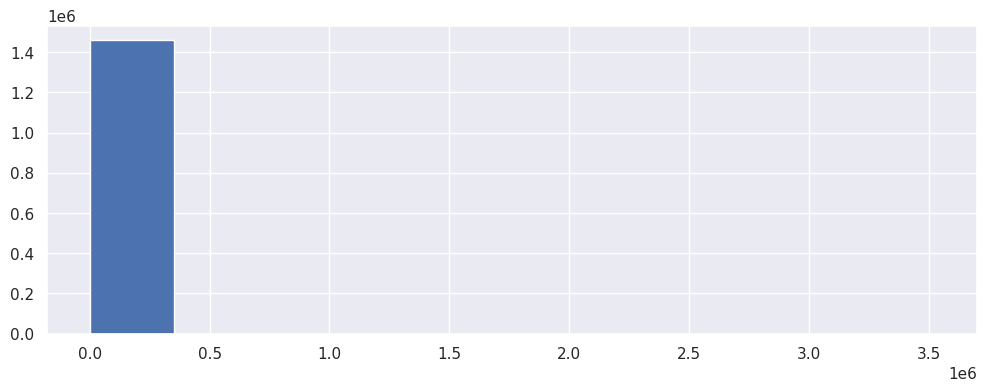

In [ ]:
data.trip_duration.hist()

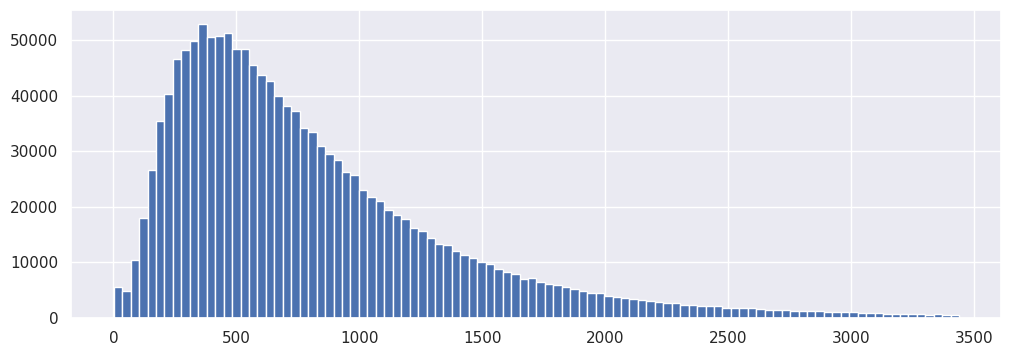

In [ ]:
data.trip_duration[data.trip_duration < data.trip_duration.quantile(0.99)].hist(bins=100)

### 2.2. Evaluation metric

The evaluation metric for this competition is Root Mean Squared Logarithmic Error:

$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

### 2.3. Target transformation

The logarithm of the target variable allows us to normalize it, which helps stabilize the variance.

In [ ]:
def transform_target(y):
  return np.log1p(y).rename('log_'+y.name)

y = transform_target(y)
y_train = transform_target(y_train)
y_test = transform_target(y_test)

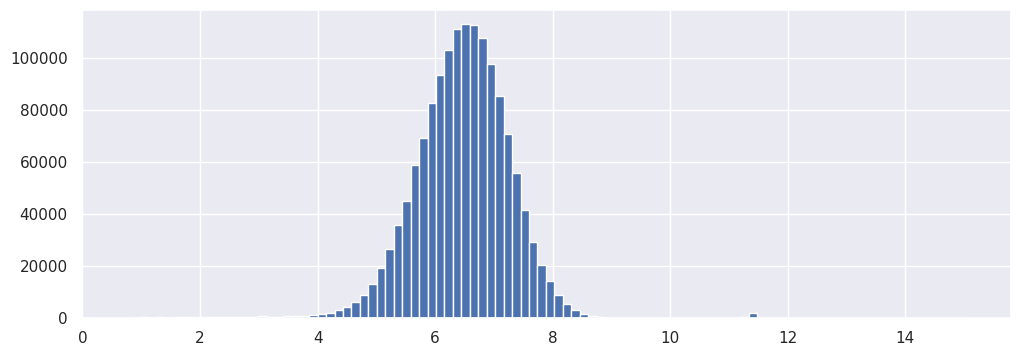

In [ ]:
y.hist(bins=100)

## Baseline

To have some starting point, calculate the value of the RMSLE metric for the best constant prediction.

In [ ]:
from sklearn.metrics import mean_squared_error

y_baseline = y_train.mean()
print(f'Baseline prediction: {y_baseline:.2f} (transformed)')
# np.expm1 is the inverse of log1p
print(f'Baseline prediction: {np.expm1(y_baseline):.0f} (seconds)')

print(f'RMSLE on train data: {mean_squared_error([y_baseline]*len(y_train), y_train, squared=False):.3f}')
print(f'RMSLE on train data: {mean_squared_error([y_baseline]*len(y_test), y_test, squared=False):.3f}')

Baseline prediction: 6.47 (transformed)
Baseline prediction: 643 (seconds)
RMSLE on train data: 0.796
RMSLE on train data: 0.795


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


In [ ]:
# data['trip_duration'].mean()

## `pickup_datetime`

### 4.1. Number of trips ~ date

Number of trips per day can be visualized.

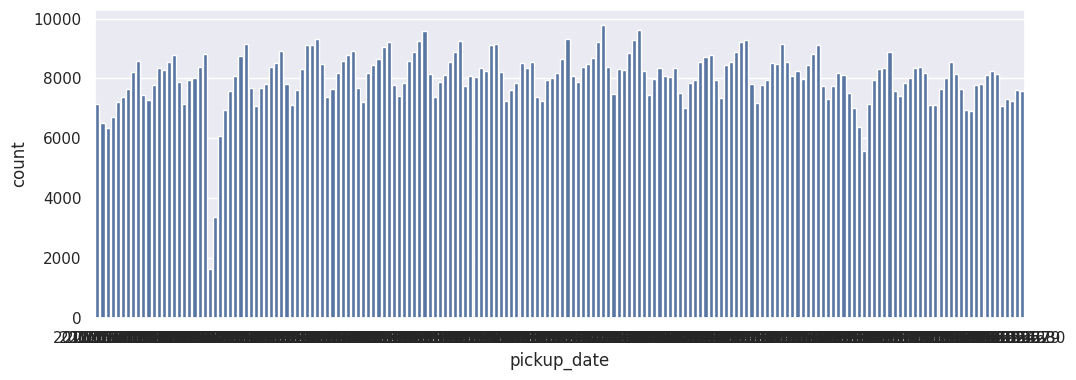

In [ ]:
X['pickup_date'] = X['pickup_datetime'].dt.date
dates = X['pickup_date'].sort_values()
g = sns.countplot(x=dates)

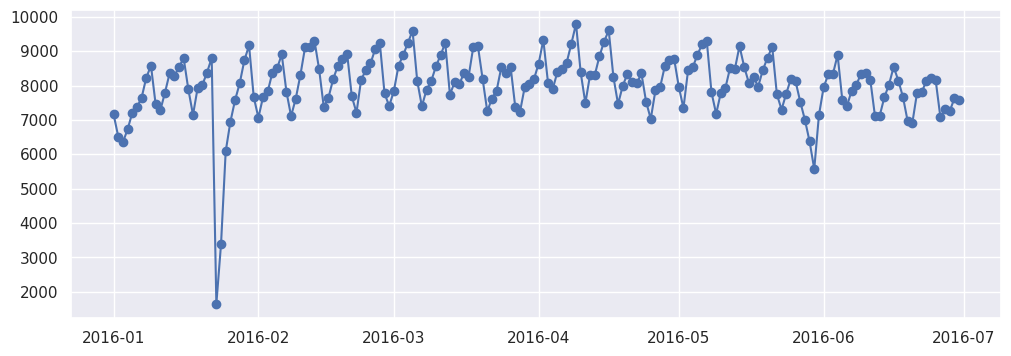

In [ ]:
plt.plot(X['pickup_date'].groupby(X['pickup_date']).count(), 'o-')

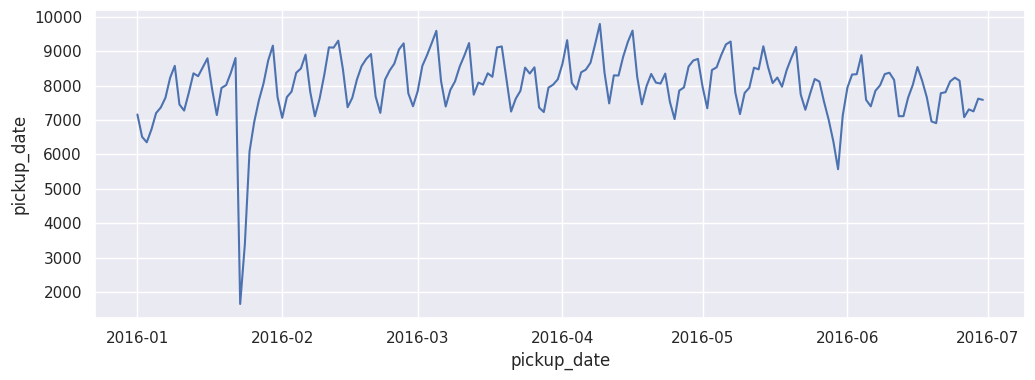

In [ ]:
sns.lineplot(X['pickup_date'].groupby(X['pickup_date']).count())

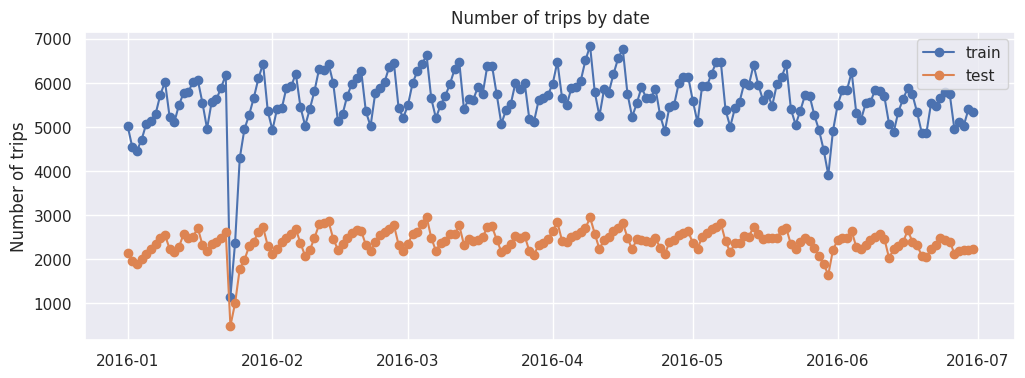

In [ ]:
plt.plot(X_train['pickup_datetime'].groupby(X_train['pickup_datetime'].dt.date).count(), 'o-', label='train')
plt.plot(X_test['pickup_datetime'].groupby(X_test['pickup_datetime'].dt.date).count(), 'o-', label='test')
plt.title('Number of trips by date')
plt.legend(loc=0)
plt.ylabel('Number of trips')
plt.show()

**Question**: You might have noticed 2 periods with too few trips compared to the usual number of trips.

In [ ]:
df_abnormal_dates = X.groupby('pickup_date').size()
abnormal_dates = df_abnormal_dates[df_abnormal_dates < 6300]
abnormal_dates  

,0
pickup_date,
2016-01-23,1648
2016-01-24,3383
2016-01-25,6084
2016-05-30,5570


### Number of trips ~ day of the week, hour of the day

In [ ]:
dict_weekday = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}

weekday = X["pickup_datetime"].dt.weekday.map(dict_weekday).rename("weekday")
hourofday = X["pickup_datetime"].dt.hour.rename("hour")

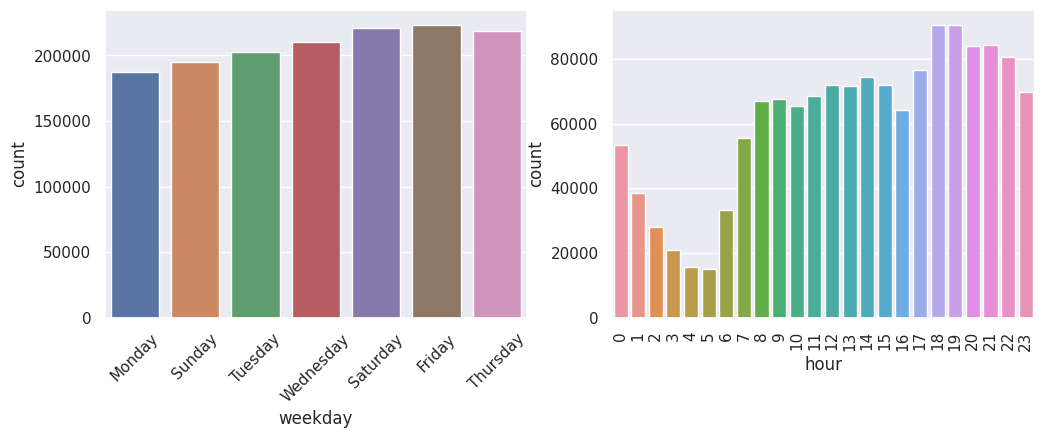

In [ ]:
fig, ax = plt.subplots(1,2)
sns.countplot(x=weekday, ax=ax[0])
ax[0].set(xlabel='weekday')
sns.countplot(x=hourofday, ax=ax[1])
ax[1].set(xlabel='hour')
ax[0].tick_params('x', labelrotation=45)
ax[1].tick_params('x', labelrotation=90)
plt.show()

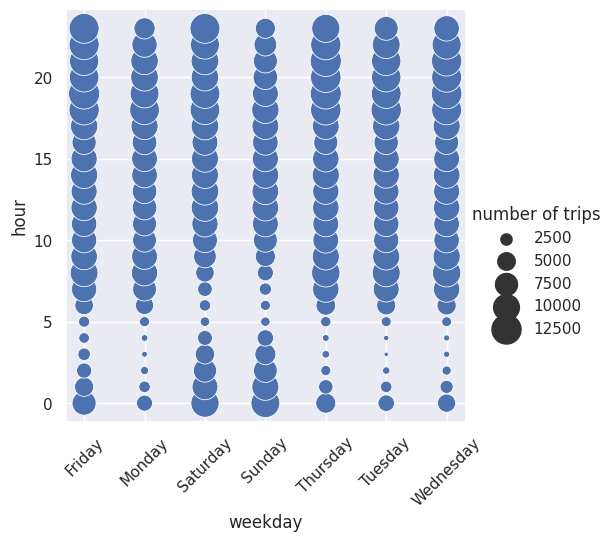

In [ ]:
data_plot = X.groupby([weekday, hourofday]).size().rename('number of trips').reset_index()
sns.relplot(data=data_plot, x='weekday', y='hour', size='number of trips', sizes=(10,500))
plt.xticks(rotation=45)
plt.show()

### Number of trips ~ hour of the day for different months

In [ ]:
month = X.pickup_datetime.dt.month.rename('month')

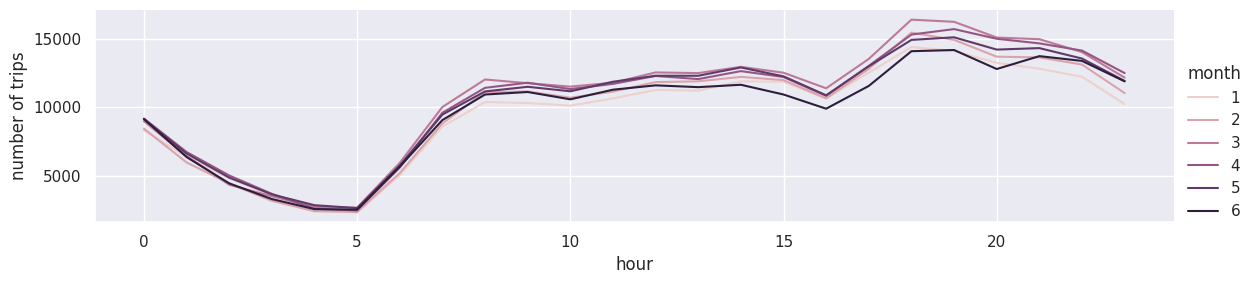

In [ ]:
data_plot = X.groupby([month, hourofday]).size().rename('number of trips').reset_index()
sns.relplot(data=data_plot, x='hour', y='number of trips', hue='month', kind='line', height=3, aspect=4)
plt.show()

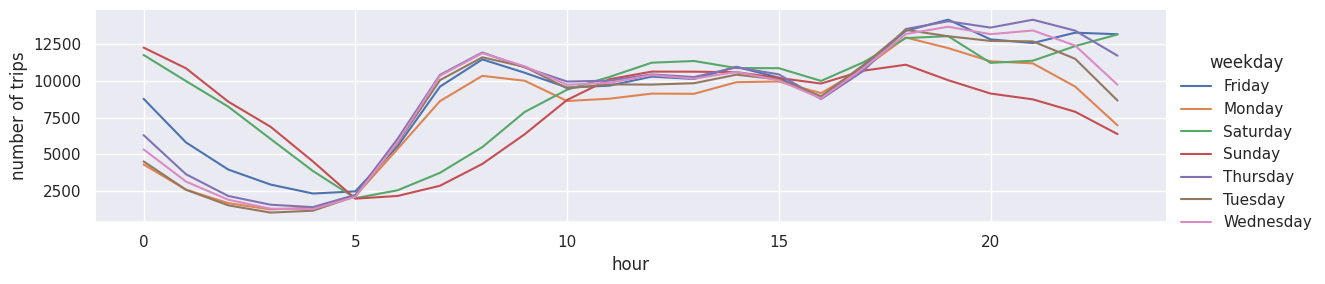

In [ ]:
data_plot = X.groupby([weekday, hourofday]).size().rename('number of trips').reset_index()
sns.relplot(data=data_plot, x='hour', y='number of trips', hue='weekday', kind='line', height=3, aspect=4)
plt.show()

### Trip duration ~ date, day of the week, hour of the day

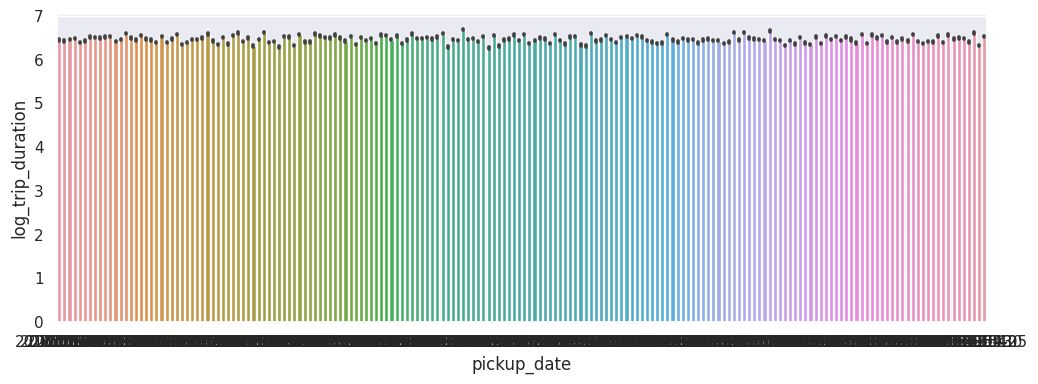

In [ ]:
sns.barplot(x=X['pickup_date'], y=y)
plt.show()

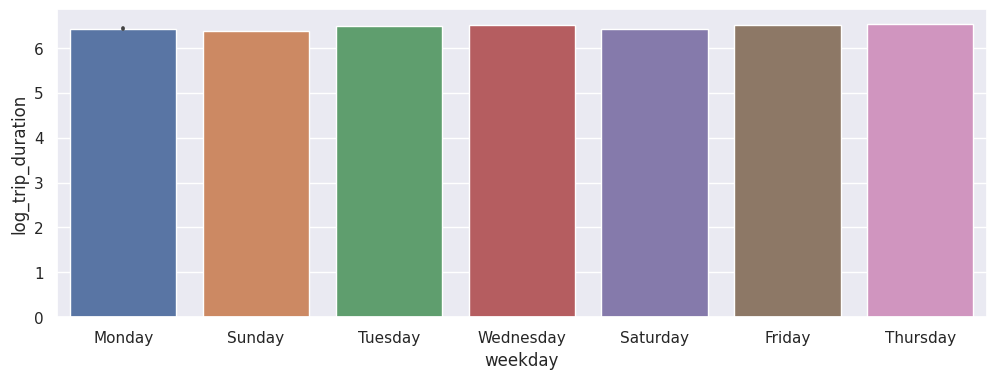

In [ ]:
sns.barplot(x=weekday, y=y)
plt.show()

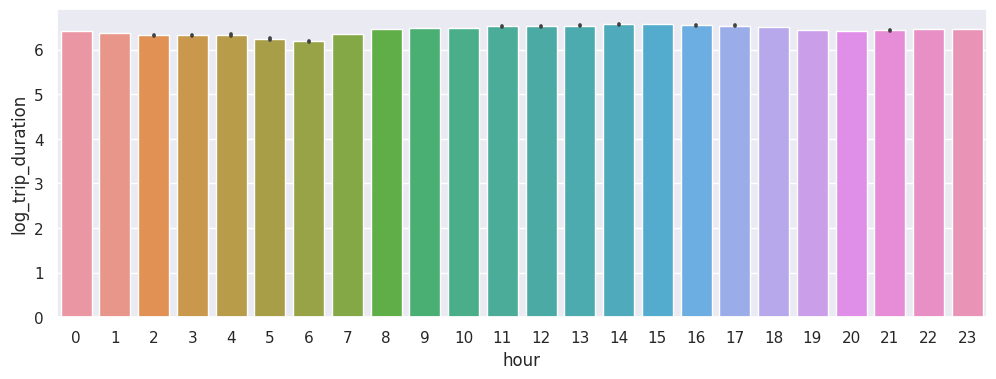

In [ ]:
sns.barplot(x=hourofday, y=y)
plt.show()

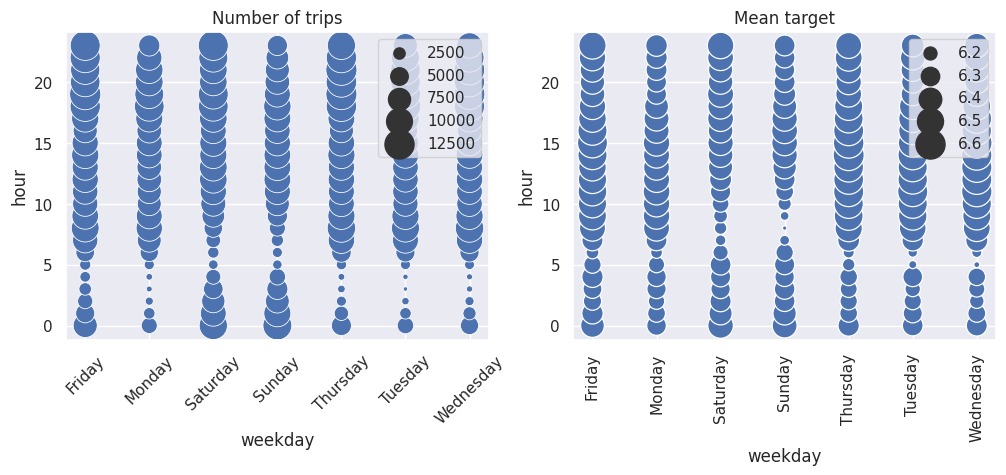

In [ ]:
fig, ax = plt.subplots(1,2)

data_plot0 = X.groupby([weekday, hourofday]).size().rename('number of trips').reset_index()
sns.scatterplot(data=data_plot0, x='weekday', y='hour', size='number of trips', sizes=(10,500), ax=ax[0])
ax[0].set_title('Number of trips')
ax[0].tick_params('x', labelrotation=45)
ax[0].legend(loc="upper right")

data_plot1 = y.groupby([weekday, hourofday]).mean().rename('mean_target').reset_index()
sns.scatterplot(data=data_plot1, x='weekday', y='hour', size='mean_target', sizes=(10,500), ax=ax[1])
ax[1].set_title('Mean target')
ax[1].tick_params('x', labelrotation=90)
ax[1].legend(loc="upper right")

plt.show()

### Feature engineering

1.   Day of week
2.   Month
3.   Hour of day
4.   If the period is "abnormal"

In [ ]:
def step1_add_features(X):
  res = X.copy()
  res['weekday'] = res['pickup_datetime'].dt.weekday
  res['month'] = res['pickup_datetime'].dt.month
  res['hour'] = res['pickup_datetime'].dt.hour
  res['abnormal_period'] = res['pickup_datetime'].dt.date.isin(abnormal_dates.index).astype(int)
  return res

X = step1_add_features(X)
X_train = step1_add_features(X_train)
X_test = step1_add_features(X_test)

In [ ]:
# check the transformation
display(X['weekday'].value_counts().head())
display(X['month'].value_counts().head())
display(X['hour'].value_counts().head())
display(X['abnormal_period'].value_counts())

4    223533
5    220868
3    218574
2    210136
1    202749
Name: weekday, dtype: int64

3    256189
4    251645
5    248487
2    238300
6    234316
Name: month, dtype: int64

18    90600
19    90308
21    84185
20    84072
22    80492
Name: hour, dtype: int64

0    1441959
1      16685
Name: abnormal_period, dtype: int64

### Ridge regression

In [ ]:
X.columns

Index(['vendor_id', 'pickup_datetime', 'passenger_count', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'store_and_fwd_flag', 'pickup_date', 'weekday', 'month', 'hour',
       'abnormal_period'],
      dtype='object')

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
num_features = ['abnormal_period', 'hour']
cat_features = ['weekday', 'month']
train_features = num_features + cat_features

column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown="ignore"), cat_features),
    ('scaling', StandardScaler(), num_features)]
)

pipeline = Pipeline(steps=[
    ('ohe_and_scaling', column_transformer),
    ('regression', Ridge())
])

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.7929
Test RMSE = 0.7919
Test R2 = 0.0077


## Coordinates analysis

Install `folium` library to visualize geographical maps.

In [ ]:
%%capture
!pip install folium

In [ ]:
import folium

folium.Map(location=(43.44626936228708, -1.553731439410459), zoom_start=50)

In [ ]:
def show_circles_on_map(data, latitude_column, longitude_column, color):
    """
    The function draws map with circles on it.
    The center of the map is the mean of coordinates passed in data.

    data: DataFrame that contains columns latitude_column and longitude_column
    latitude_column: string, the name of column for latitude coordinates
    longitude_column: string, the name of column for longitude coordinates
    color: string, the color of circles to be drawn
    """

    location = (data[latitude_column].mean(), data[longitude_column].mean())
    m = folium.Map(location=location)

    for _, row in data.iterrows():
        folium.Circle(
            radius=100,
            location=(row[latitude_column], row[longitude_column]),
            color=color,
            fill_color=color,
            fill=True
        ).add_to(m)

    return m

In [ ]:
show_circles_on_map(data.sample(1000), "pickup_latitude", "pickup_longitude", "blue")

### Distance estimation

The duration of the trip depends on the distance and the time: $t = s / v_{\text{mean}}$. Distance would be very important for predicting duration. We cannot calculate the exact distance corresponding to a trip, but we can estimate it by calculating the minimum distance between the departure and arrival points. To correctly calculate the distance between two points on Earth, we can use the `haversine` function.

### Haversine Formula

The Haversine formula calculates the great-circle distance between two points on a sphere given their longitudes and latitudes.

Let:  
- $\phi_1, \phi_2$ be the latitudes in radians  
- $\lambda_1, \lambda_2$ be the longitudes in radians  
- $\Delta\phi = \phi_2 - \phi_1$  
- $\Delta\lambda = \lambda_2 - \lambda_1$  
- $R$ be the Earth's radius (mean radius = 6,371 km)

Then:

$$
a = \sin^2\left(\frac{\Delta\phi}{2}\right) + \cos(\phi_1) \cdot \cos(\phi_2) \cdot \sin^2\left(\frac{\Delta\lambda}{2}\right)
$$

$$
d = R \cdot 2 \cdot \arcsin \left(\sqrt{a}\right)
$$


In [ ]:
def haversine_array(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    AVG_EARTH_RADIUS = 6371  # in km
    lat = lat2 - lat1
    lng = lng2 - lng1
    d = np.sin(lat * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(lng * 0.5) ** 2
    h = 2 * AVG_EARTH_RADIUS * np.arcsin(np.sqrt(d))
    return h

In [ ]:
distance_haversine = haversine_array(X.pickup_latitude, X.pickup_longitude, X.dropoff_latitude, X.dropoff_longitude)

Since the target variable is the logarithm of the trip duration and in order to try to build a linear model to predict these values, it is necessary to calculate the logarithm of the distance: $\log t = \log s - \log{v_{\text{mean}}}$.

In [ ]:
log_distance_haversine = np.log1p(distance_haversine)

Check whether the logarithm of the haversine distance correlates better with the target variable than the distance itself.

In [ ]:
print(f'Correlation between target and distance_haversine: {np.corrcoef(x=distance_haversine,y=y)[0,1]:.2f}')
print(f'Correlation between target and log_distance_haversine: {np.corrcoef(x=log_distance_haversine,y=y)[0,1]:.2f}')

Correlation between target and distance_haversine: 0.57
Correlation between target and log_distance_haversine: 0.75


### Speed estimation

Calculate the average speed for each trip in the training sample: `haversine` divided by `trip_duration`. Display the distribution of average speed values.

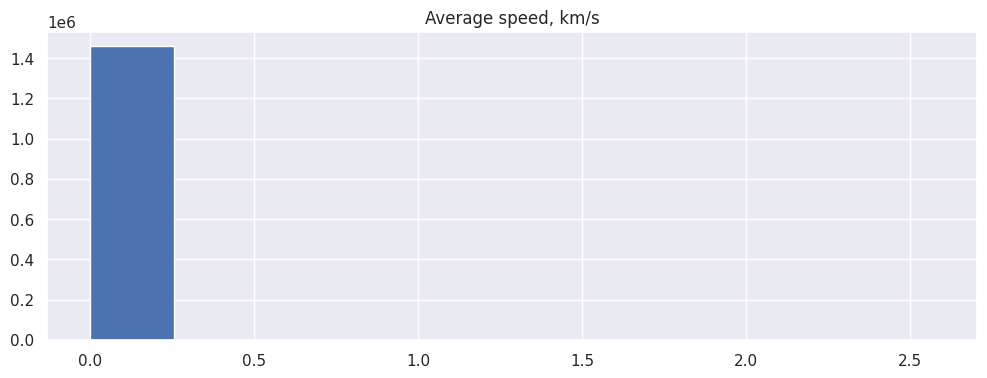

In [ ]:
avg_speed = distance_haversine / np.expm1(y)
avg_speed.hist()
plt.title('Average speed, km/s')
plt.show()

As you can see from this histogram, there are outliers. Filter the data, for example by removing values greater than a certain percentile, and display again the distribution.

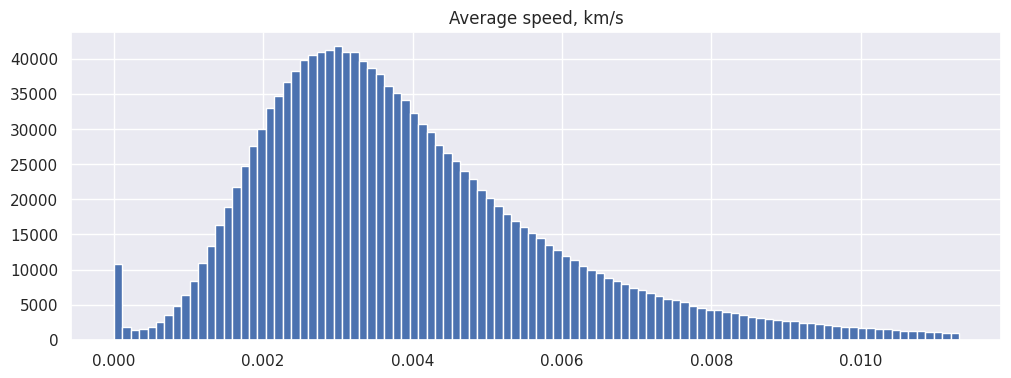

In [ ]:
avg_speed[avg_speed<avg_speed.quantile(0.99)].hist(bins=100)
plt.title('Average speed, km/s')
plt.show()

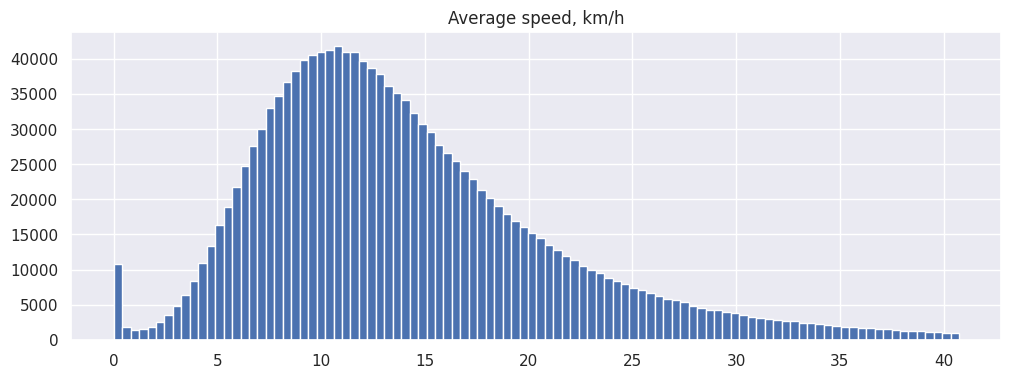

In [ ]:
(avg_speed[avg_speed<avg_speed.quantile(0.99)]*3600).hist(bins=100)
plt.title('Average speed, km/h')
plt.show()

For each tuple (day of the week, time of day) calculate the median speed. Display a heatmap with the results.

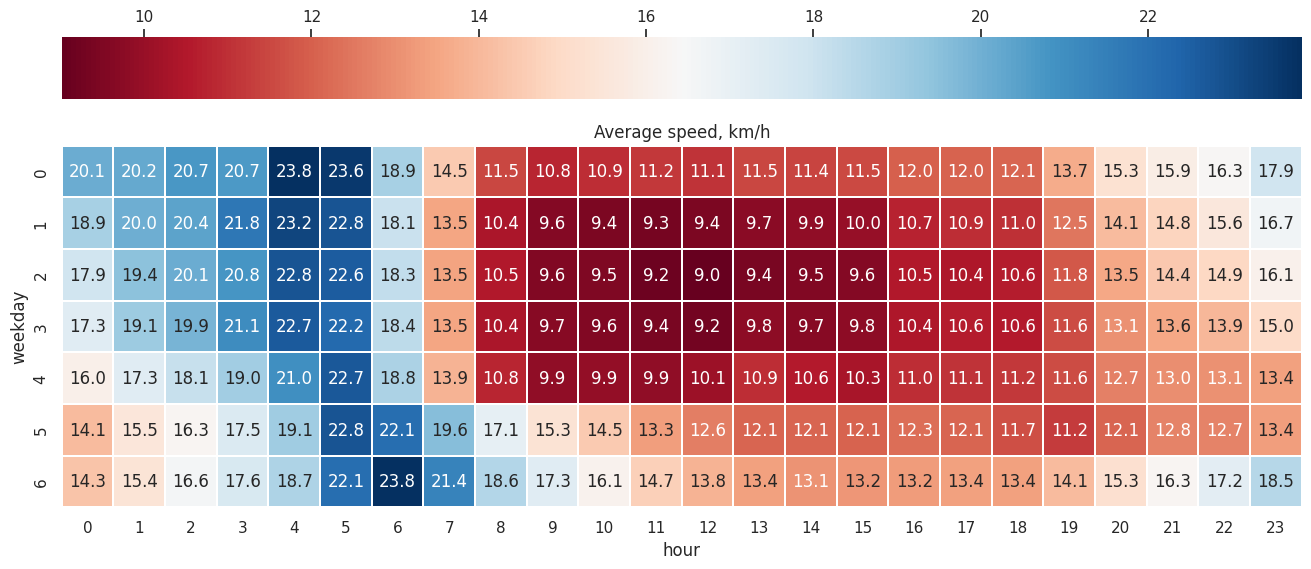

In [ ]:
data_plot = avg_speed.groupby([X['weekday'], X['hour']]).median().rename('avg_speed').reset_index()
data_plot = data_plot.pivot(index='weekday', columns='hour', values='avg_speed')

f, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(data_plot*3600, annot=True, fmt=".1f", linewidths=0.1, square=True, cmap="RdBu", cbar_kws=dict(use_gridspec=False, location="top"))
plt.title('Average speed, km/h')
plt.show()

The variable containing the speed must be dropped before training a linear model. (cf. https://en.wikipedia.org/wiki/Multicollinearity).

Add new binary variables `high traffic trip` and `high speed trip` .

A trip is considered **high traffic** if:

- It occurs on a **weekday (Monday to Friday)** between **8:00 and 19:00**,  
  i.e.  
  $$
  0 \leq \text{weekday} \leq 4 \quad \text{and} \quad 8 \leq \text{hour} \leq 19
  $$

**OR**

- It occurs on a **Saturday** between **13:00 and 20:00**,  
  i.e.  
  $$
  \text{weekday} = 5 \quad \text{and} \quad 13 \leq \text{hour} \leq 20
  $$

A trip is considered **high speed** if:

- It occurs on a **weekday (Monday to Friday)** between **2:00 and 5:00**,  
  i.e.  
  $$
  0 \leq \text{weekday} \leq 4 \quad \text{and} \quad 2 \leq \text{hour} \leq 5
  $$

**OR**

- It occurs on a **weekend (Saturday or Sunday)** between **4:00 and 7:00**,  
  i.e.  
  $$
  5 \leq \text{weekday} \leq 6 \quad \text{and} \quad 4 \leq \text{hour} \leq 7
  $$


In [ ]:
def is_high_traffic_trip(X):
    return (
        (X["hour"] >= 8) & (X["hour"] <= 19) & (X["weekday"] >= 0) & (X["weekday"] <= 4)
    ) | ((X["hour"] >= 13) & (X["hour"] <= 20) & (X["weekday"] == 5))


def is_high_speed_trip(X):
    return (
        (X["hour"] >= 2) & (X["hour"] <= 5) & (X["weekday"] >= 0) & (X["weekday"] <= 4)
    ) | (
        (X["hour"] >= 4) & (X["hour"] <= 7) & (X["weekday"] >= 5) & (X["weekday"] <= 6)
    )

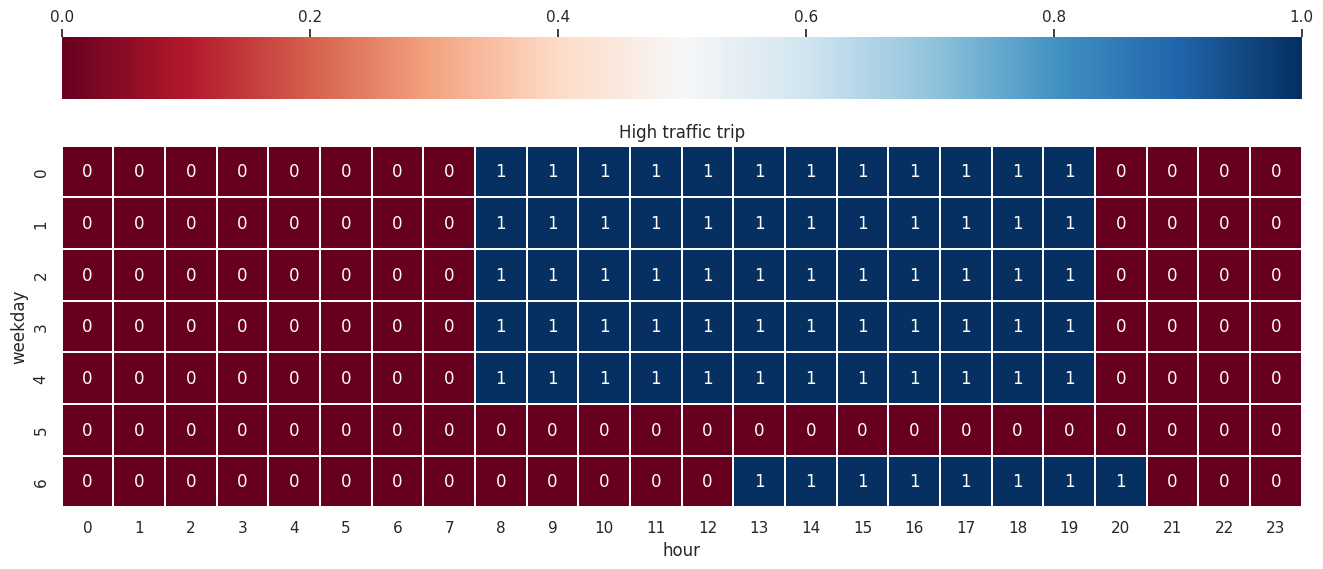

In [ ]:
# test is_high_traffic_trip function
high_traffic_trip_vec = is_high_traffic_trip(X).astype(int).rename('is_high_traffic_trip')

data_plot = pd.concat([X[['weekday', 'hour']], high_traffic_trip_vec], axis=1)
data_plot = data_plot.groupby(['weekday', 'hour'])['is_high_traffic_trip'].mean().reset_index()
data_plot = data_plot.pivot(index='weekday', columns='hour', values='is_high_traffic_trip')

f, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(data_plot, annot=True, fmt=".0f", linewidths=0.1, square=True, cmap="RdBu", cbar_kws=dict(use_gridspec=False, location="top"))
plt.title('High traffic trip')
plt.show()

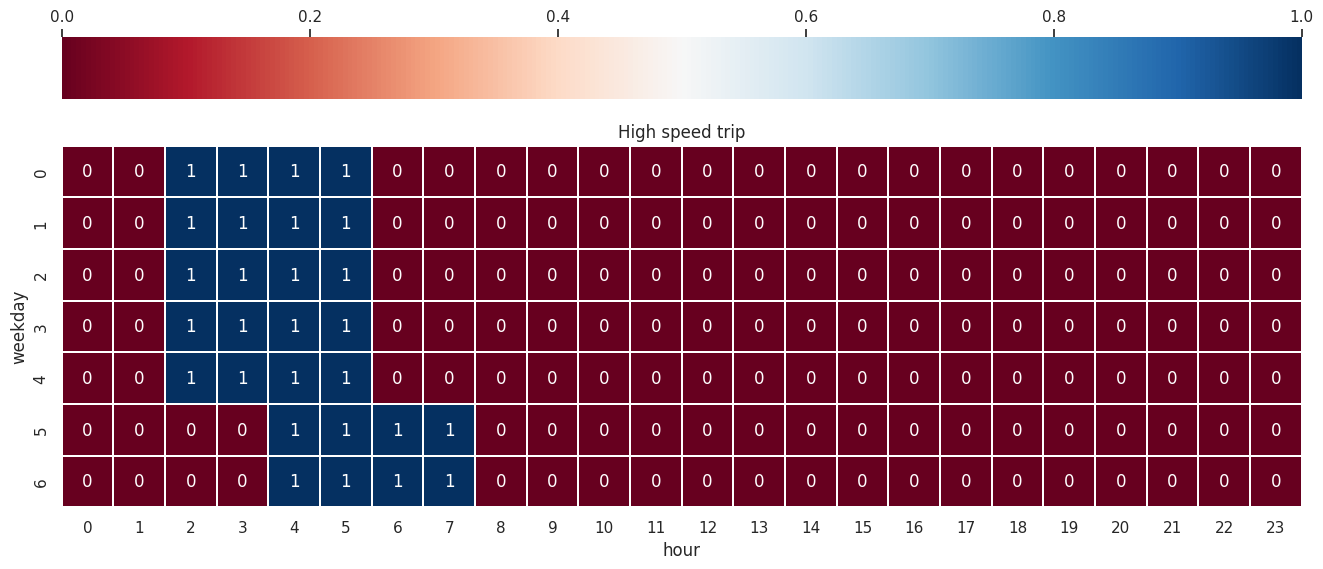

In [ ]:
# test is_high_traffic_trip function
high_speed_trip_vec = is_high_speed_trip(X).astype(int).rename('is_high_speed_trip')

data_plot = pd.concat([X[['weekday', 'hour']], high_speed_trip_vec], axis=1)
data_plot = data_plot.groupby(['weekday', 'hour'])['is_high_speed_trip'].mean().reset_index()
data_plot = data_plot.pivot(index='weekday', columns='hour', values='is_high_speed_trip')

f, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(data_plot, annot=True, fmt=".0f", linewidths=0.1, square=True, cmap="RdBu", cbar_kws=dict(use_gridspec=False, location="top"))
plt.title('High speed trip')
plt.show()

### Outliers

On the map you can see some points that are quite far from Manhattan.

In [ ]:
def is_rare_point(
    X, latitude_column, longitude_column, qmin_lat, qmax_lat, qmin_lon, qmax_lon
):
    lat_min = X[latitude_column].quantile(qmin_lat)
    lat_max = X[latitude_column].quantile(qmax_lat)
    lon_min = X[longitude_column].quantile(qmin_lon)
    lon_max = X[longitude_column].quantile(qmax_lon)

    res = (
        (X[latitude_column] < lat_min)
        | (X[latitude_column] > lat_max)
        | (X[longitude_column] < lon_min)
        | (X[longitude_column] > lon_max)
    )
    return res

In [ ]:
latitude_column, longitude_column = "pickup_latitude", "pickup_longitude"

is_rare_point_vec = is_rare_point(X, latitude_column, longitude_column, 0.01, 0.995, 0, 0.95)
m = show_circles_on_map(data[~is_rare_point_vec].sample(1000), latitude_column, longitude_column, "blue")

rare_points = X[[latitude_column, longitude_column]][is_rare_point_vec]
color_rare = 'red'

for _, row in rare_points.sample(100).iterrows():
    folium.Circle(
        radius=100,
        location=(row[latitude_column], row[longitude_column]),
        color=color_rare,
        fill_color=color_rare,
        fill=True
    ).add_to(m)
m

In [ ]:
latitude_column, longitude_column = "dropoff_latitude", "dropoff_longitude"

is_rare_point_vec = is_rare_point(
    X, latitude_column, longitude_column, 0.01, 0.995, 0.005, 0.95
)
m = show_circles_on_map(
    data[~is_rare_point_vec].sample(1000), latitude_column, longitude_column, "blue"
)

rare_points = X[[latitude_column, longitude_column]][is_rare_point_vec]
color_rare = "red"

for _, row in rare_points.sample(100).iterrows():
    folium.Circle(
        radius=100,
        location=(row[latitude_column], row[longitude_column]),
        color=color_rare,
        fill_color=color_rare,
        fill=True,
    ).add_to(m)
m

### Check new features

In [ ]:
def step2_add_features(X):
  res = X.copy()
  distance_haversine = haversine_array(res.pickup_latitude, res.pickup_longitude, res.dropoff_latitude, res.dropoff_longitude)
  res['log_distance_haversine'] = np.log1p(distance_haversine)
  res['is_high_traffic_trip'] = is_high_traffic_trip(X).astype(int)
  res['is_high_speed_trip'] = is_high_traffic_trip(X).astype(int)
  res['is_rare_pickup_point'] = is_rare_point(X, "pickup_latitude", "pickup_longitude", 0.01, 0.995, 0, 0.95).astype(int)
  res['is_rare_dropoff_point'] = is_rare_point(X, "dropoff_latitude", "dropoff_longitude", 0.01, 0.995, 0.005, 0.95).astype(int)

  return res

X = step2_add_features(X)
X_train = step2_add_features(X_train)
X_test = step2_add_features(X_test)

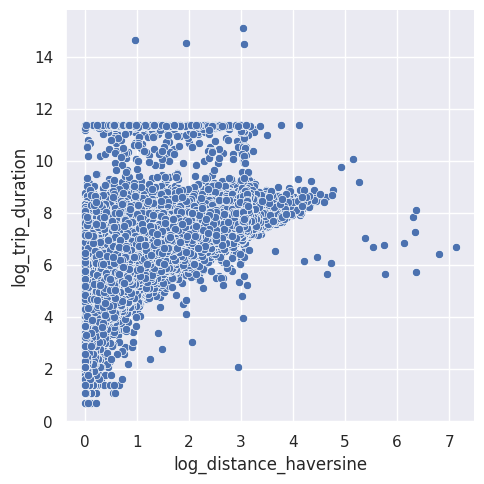

In [ ]:
sns.relplot(data=X, x='log_distance_haversine', y=y)
plt.show()

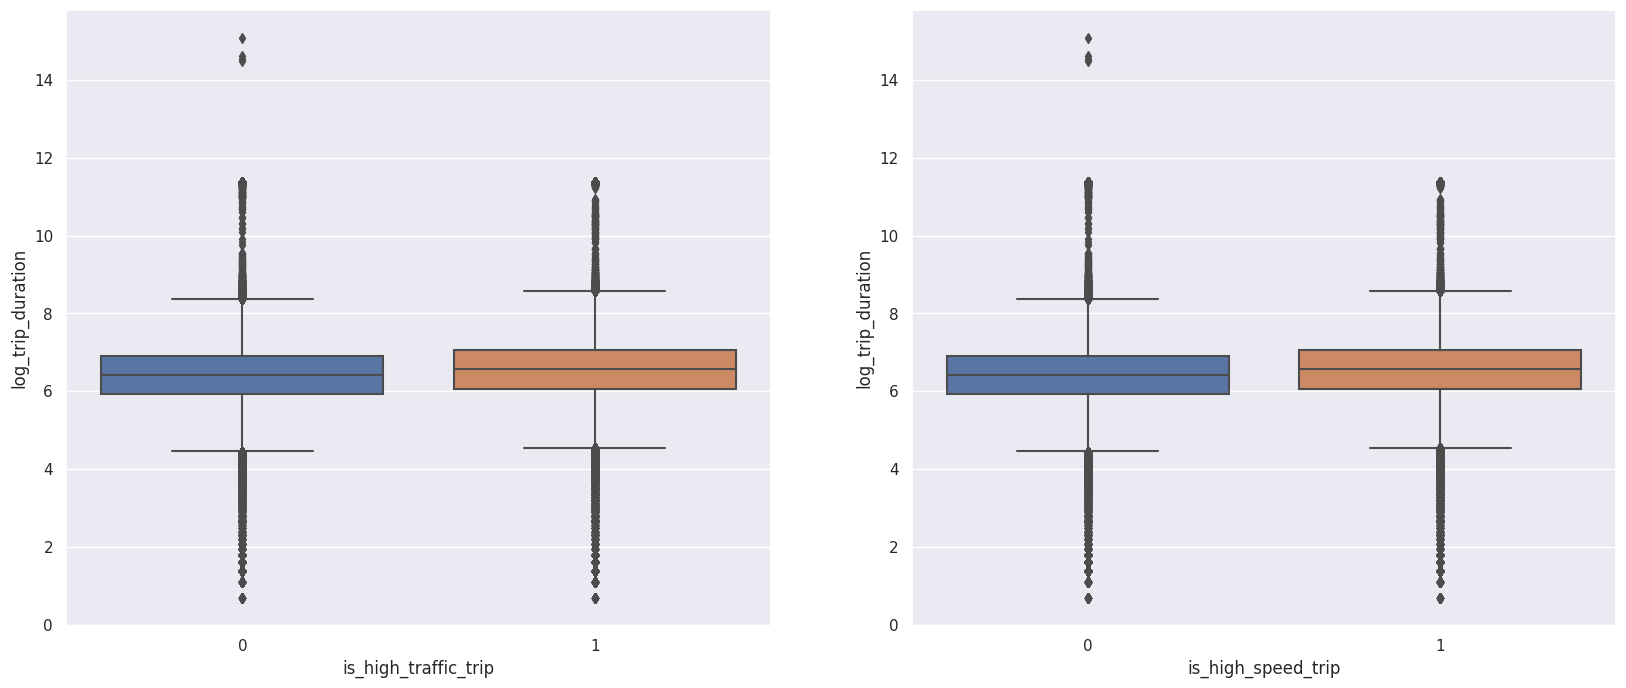

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

sns.boxplot(x=X['is_high_traffic_trip'], y=y, ax=ax[0])
sns.boxplot(x=X['is_high_speed_trip'], y=y, ax=ax[1])
plt.show()

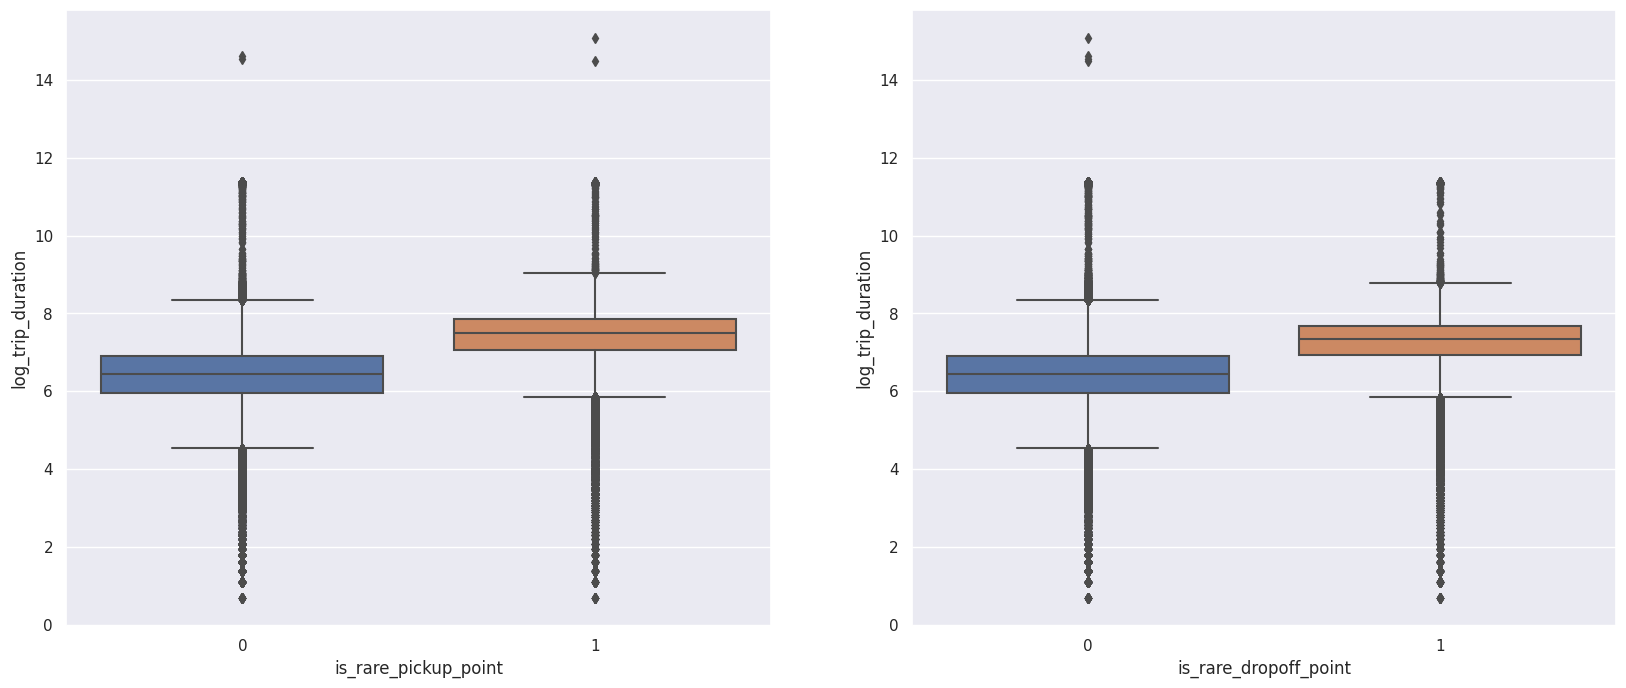

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

sns.boxplot(x=X['is_rare_pickup_point'], y=y, ax=ax[0])
sns.boxplot(x=X['is_rare_dropoff_point'], y=y, ax=ax[1])
plt.show()

### Ridge regression

* Use only the features we have worked with up to now.

In [ ]:
X.columns

Index(['vendor_id', 'pickup_datetime', 'passenger_count', 'pickup_longitude',
       'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'store_and_fwd_flag', 'pickup_date', 'weekday', 'month', 'hour',
       'abnormal_period', 'log_distance_haversine', 'is_high_traffic_trip',
       'is_high_speed_trip', 'is_rare_pickup_point', 'is_rare_dropoff_point'],
      dtype='object')

In [ ]:
num_features = [
    "log_distance_haversine",
    "hour",
    "abnormal_period",
    "is_high_traffic_trip",
    "is_high_speed_trip",
    "is_rare_pickup_point",
    "is_rare_dropoff_point",
]
cat_features = ["weekday", "month"]
train_features = num_features + cat_features

column_transformer = ColumnTransformer(
    [
        ("ohe", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("scaling", StandardScaler(), num_features),
    ]
)

pipeline = Pipeline(
    steps=[("ohe_and_scaling", column_transformer), ("regression", Ridge())]
)

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.4954
Test RMSE = 0.4943
Test R2 = 0.6134


## Other features analysis

### `vendor_id`, `passenger_count`, `store_and_fwd_flag`

There are 3 more variables: `vendor_id`, `passenger_count` and `store_and_fwd_flag`.

In [ ]:
X['vendor_id'].value_counts()

2    780302
1    678342
Name: vendor_id, dtype: int64

In [ ]:
X['passenger_count'].value_counts()

1    1033540
2     210318
5      78088
3      59896
6      48333
4      28404
0         60
7          3
9          1
8          1
Name: passenger_count, dtype: int64

In [ ]:
X['store_and_fwd_flag'].value_counts()

N    1450599
Y       8045
Name: store_and_fwd_flag, dtype: int64

Display the distribution of the target by the values of the following variables: `vendor_id`, `passenger_count` and `store_and_fwd_flag`.

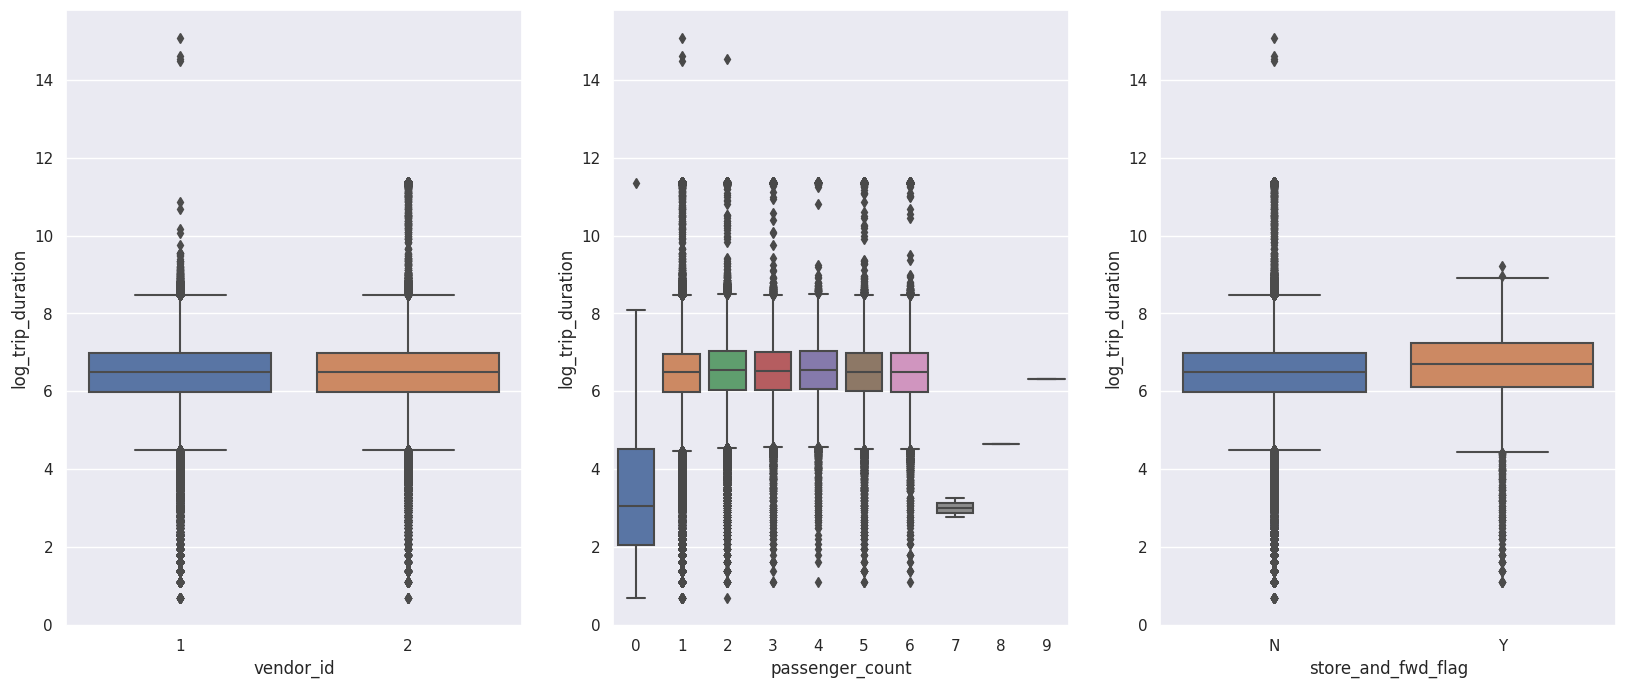

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))

sns.boxplot(x=X['vendor_id'], y=y, ax=ax[0])
sns.boxplot(x=X['passenger_count'], y=y, ax=ax[1])
sns.boxplot(x=X['store_and_fwd_flag'], y=y, ax=ax[2])
plt.show()

Change the `vendor_id` and `store_and_fwd_flag` variables so that their values are: $\{0;1\}$.

In [ ]:
def step3_process_features(X):
  res = X.copy()
  res['vendor_id'] = res['vendor_id'].map({1:0, 2:1})
  res['store_and_fwd_flag'] = res['store_and_fwd_flag'].map({'N':0, 'Y':1})
  res.loc[res['passenger_count'] > 6, 'passenger_count'] = 6

  return res

X = step3_process_features(X)
X_train = step3_process_features(X_train)
X_test = step3_process_features(X_test)

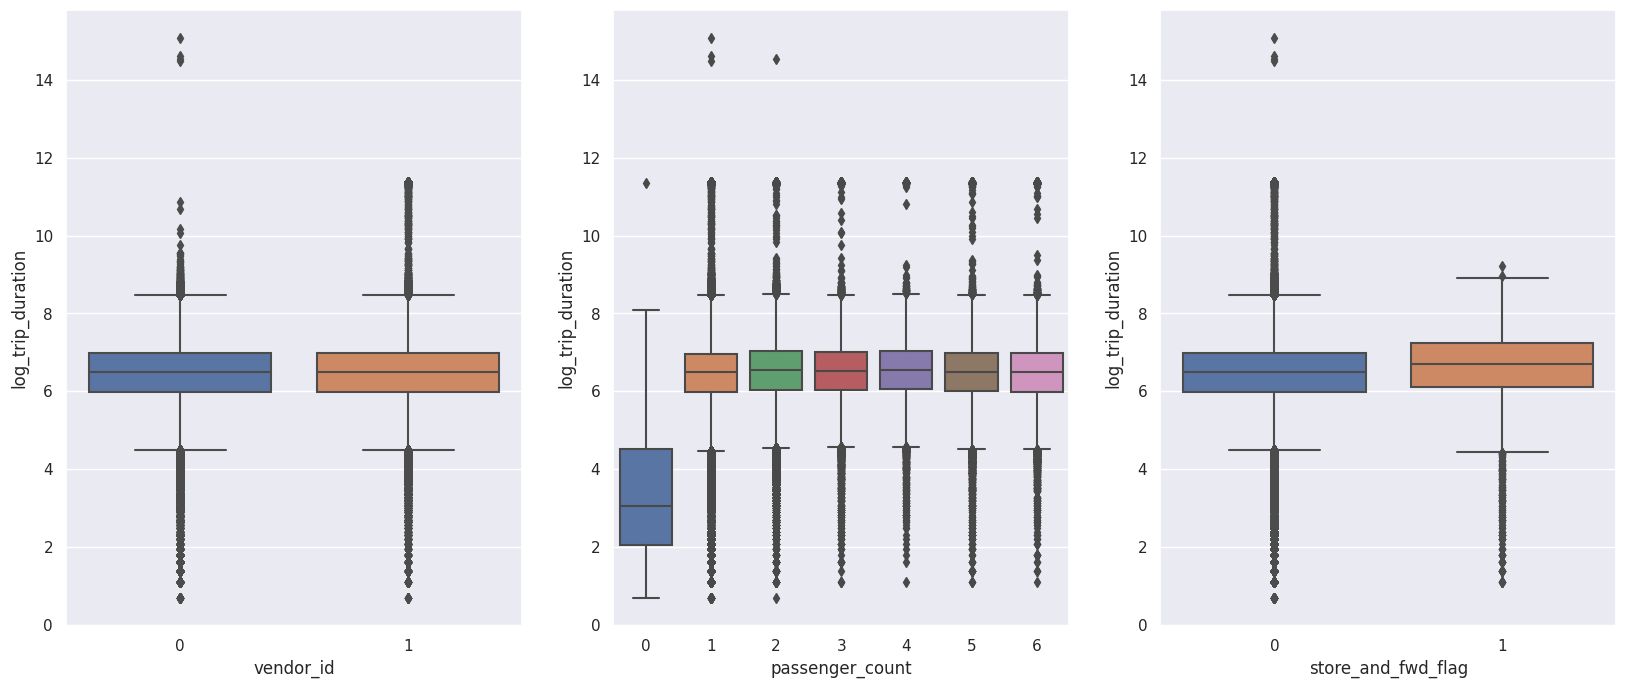

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 8))

sns.boxplot(x=X['vendor_id'], y=y, ax=ax[0])
sns.boxplot(x=X['passenger_count'], y=y, ax=ax[1])
sns.boxplot(x=X['store_and_fwd_flag'], y=y, ax=ax[2])
plt.show()

try '`vendor_id`', '`store_and_fwd_flag`'

In [ ]:
num_features = [
    "log_distance_haversine",
    "hour",
    "abnormal_period",
    "is_high_traffic_trip",
    "is_high_speed_trip",
    "is_rare_pickup_point",
    "is_rare_dropoff_point",
    "vendor_id",
    "store_and_fwd_flag",
]
cat_features = ["weekday", "month"]
train_features = num_features + cat_features

column_transformer = ColumnTransformer(
    [
        ("ohe", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("scaling", StandardScaler(), num_features),
    ]
)

pipeline = Pipeline(
    steps=[("ohe_and_scaling", column_transformer), ("regression", Ridge())]
)

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.4952
Test RMSE = 0.4942
Test R2 = 0.6136


try '`passenger_count`'


In [ ]:
num_features = [
    "log_distance_haversine",
    "hour",
    "abnormal_period",
    "is_high_traffic_trip",
    "is_high_speed_trip",
    "is_rare_pickup_point",
    "is_rare_dropoff_point",
    "passenger_count",
]
cat_features = ["weekday", "month"]
train_features = num_features + cat_features

column_transformer = ColumnTransformer(
    [
        ("ohe", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("scaling", StandardScaler(), num_features),
    ]
)

pipeline = Pipeline(
    steps=[("ohe_and_scaling", column_transformer), ("regression", Ridge())]
)

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.4952
Test RMSE = 0.4942
Test R2 = 0.6136


Dropping useless features.

In [ ]:
def undo_step3_process_features(X):
  res = X.copy()
  res.drop(columns=['vendor_id', 'store_and_fwd_flag', 'passenger_count'])

  return res

X = undo_step3_process_features(X)
X_train = undo_step3_process_features(X_train)
X_test = undo_step3_process_features(X_test)

## Improving the model

### 7.1. Cleaning data

There are outliers in the data: trips with too short duration or too long distance. Display the distribution of the abovementionned variables, select observations corresponding to the values of these variables that could be considered as outliers and drop them from the sample.

Note that although these values appear to be outliers, the test sample will most likely contain objects with the "outlier" values of the target variable and/or the other variables. As a result, it is possible that cleaning up the training sample will lead to a deterioration in the quality of the test. However, it is always preferable to remove outliers to make the model more interpretable.

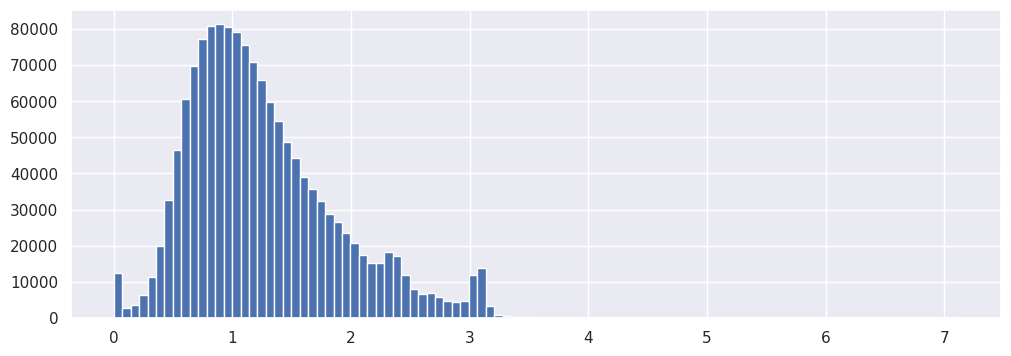

In [ ]:
X['log_distance_haversine'].hist(bins=100)

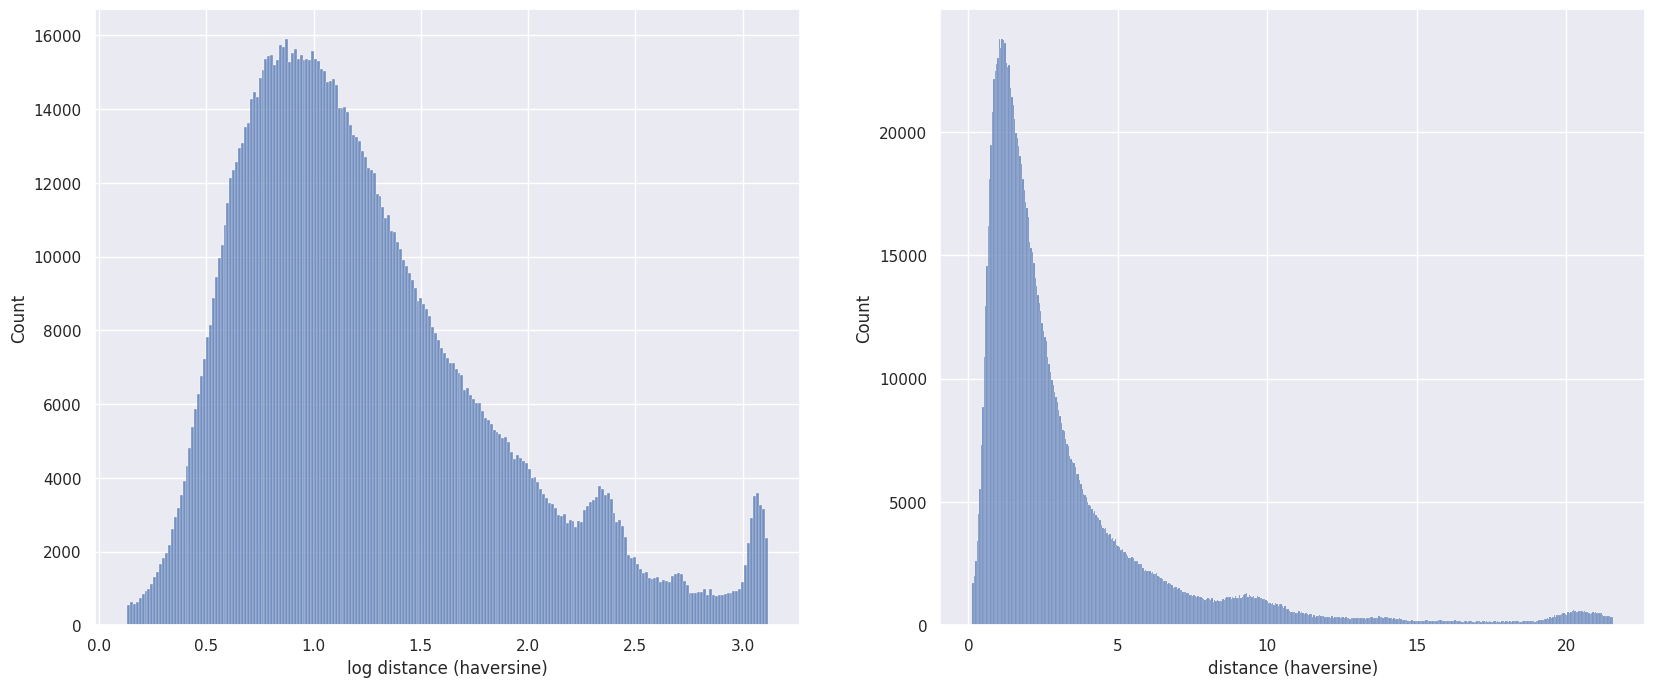

In [ ]:
d = X['log_distance_haversine']
d_min = d.quantile(0.01)
d_max = d.quantile(0.995)
d_new = d[(d > d_min) & (d < d_max)]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

sns.histplot(x=d_new, ax=ax[0])
ax[0].set(xlabel='log distance (haversine)')
sns.histplot(x=np.expm1(d_new), ax=ax[1])
ax[1].set(xlabel='distance (haversine)')
plt.show()

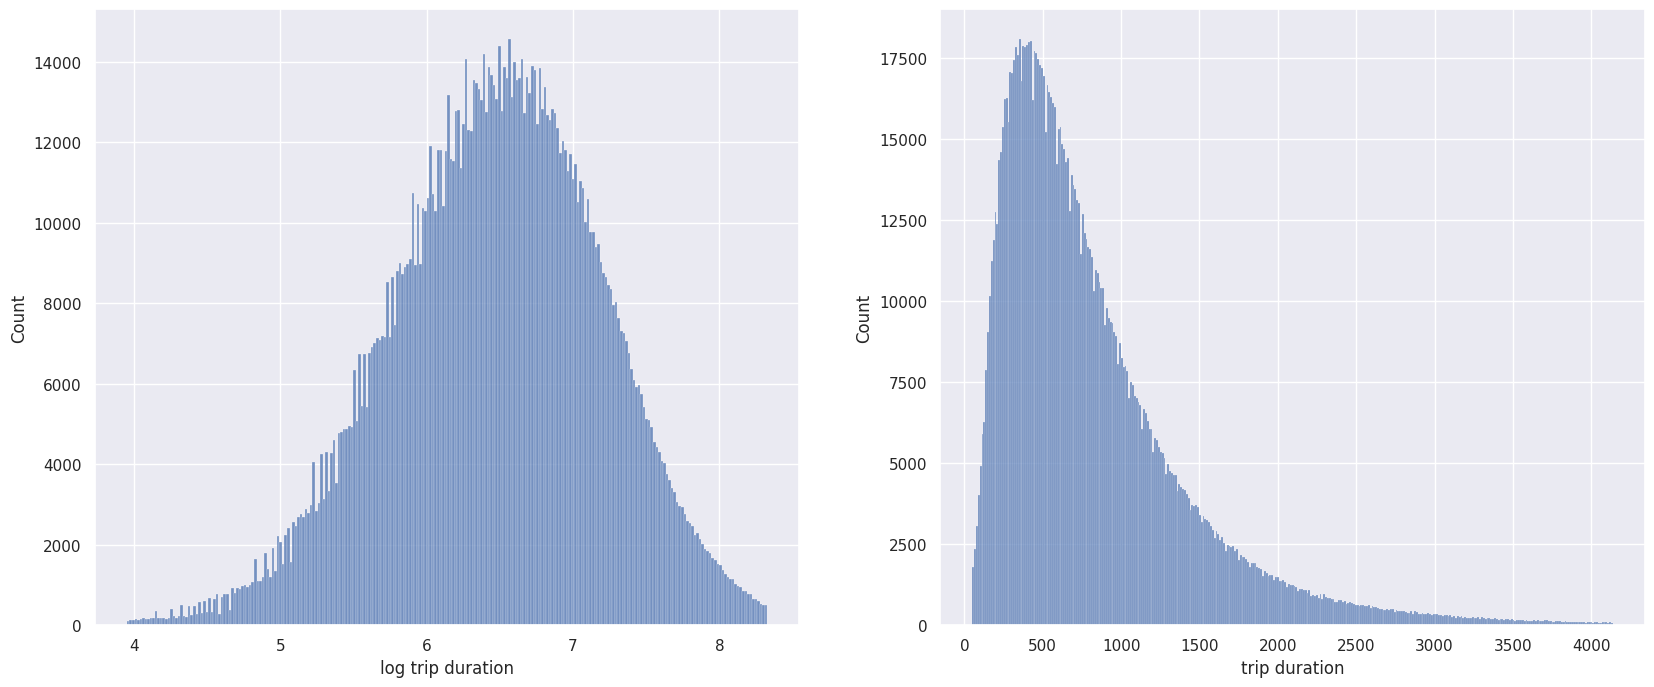

In [ ]:
y_min = y.quantile(0.005)
y_max = y.quantile(0.995)
y_new = y[(y > y_min) & (y < y_max)]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

sns.histplot(x=y_new, ax=ax[0])
ax[0].set(xlabel='log trip duration')
sns.histplot(x=np.expm1(y_new), ax=ax[1])
ax[1].set(xlabel='trip duration')
plt.show()

In [ ]:
def step4_remove_outliers(X, y):
    res = X.copy()

    d = res["log_distance_haversine"]
    d_min = d.quantile(0.01)
    d_max = d.quantile(0.995)
    cond_distance = (d > d_min) & (d < d_max)

    y_min = y.quantile(0.005)
    y_max = y.quantile(0.995)
    cond_time = (y > y_min) & (y < y_max)

    cond_non_outliers = cond_distance & cond_time

    return X[cond_non_outliers], y[cond_non_outliers]

In [ ]:
X_temp, y_temp = step4_remove_outliers(X, y)
display(X.shape, y.shape)
display(X_temp.shape, y_temp.shape)
len(X_temp) / len(X)

(1458644, 18)

(1458644,)

(1428843, 18)

(1428843,)

0.9795693808770337

In [ ]:
X_train, y_train = step4_remove_outliers(X_train, y_train)
X, y = pd.concat([X_train, X_test]), pd.concat([y_train, y_test])

In [ ]:
display(X.shape, y.shape)

(1437761, 17)

(1437761,)

There are many categorical variables. Some categories are very rare and using them can lead to overfitting. Try to combine (very) rare categories into fewer categories.

In [ ]:
X['weekday'].value_counts()

4    220186
5    218065
3    215212
2    207133
1    199993
6    192543
0    184629
Name: weekday, dtype: int64

In [ ]:
X['month'].value_counts()

3    252751
4    248126
5    244521
2    235284
6    230575
1    226504
Name: month, dtype: int64

In [ ]:
def encode_weekday(x):
    if x == 0:
        return 0
    if x == 5:
        return 2
    if x == 6:
        return 3
    return 1


def step5_process_categorical_features(X):
    res = X.copy()
    res["weekday"] = res["weekday"].apply(encode_weekday)

    return res


# test the function
step5_process_categorical_features(X)["weekday"].value_counts()

1    842524
2    218065
3    192543
0    184629
Name: weekday, dtype: int64

In [ ]:
X = step5_process_categorical_features(X)
X_train = step5_process_categorical_features(X_train)
X_test = step5_process_categorical_features(X_test)

Train the model on clean data and evaluate it.

In [ ]:
num_features = ['log_distance_haversine', 'hour',
                'abnormal_period', 'is_high_traffic_trip', 'is_high_speed_trip',
                'is_rare_pickup_point', 'is_rare_dropoff_point']
cat_features = ['weekday', 'month']
train_features = num_features + cat_features

column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown="ignore"), cat_features),
    ('scaling', StandardScaler(), num_features)]
)

pipeline = Pipeline(steps=[
    ('ohe_and_scaling', column_transformer),
    ('regression', Ridge())
])

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.4163
Test RMSE = 0.4947
Test R2 = 0.6127


### Ridge vs. Lasso

Tune hyperparameters of `Lasso` and `Ridge` algorithms.

In [ ]:
from sklearn.linear_model import Lasso

num_features = [
    "log_distance_haversine",
    "hour",
    "abnormal_period",
    "is_high_traffic_trip",
    "is_high_speed_trip",
    "is_rare_pickup_point",
    "is_rare_dropoff_point",
]
cat_features = ["weekday", "month"]
train_features = num_features + cat_features

column_transformer = ColumnTransformer(
    [
        ("ohe", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("scaling", StandardScaler(), num_features),
    ]
)

pipeline = Pipeline(
    steps=[("ohe_and_scaling", column_transformer), ("regression", Lasso(alpha=0.5))]
)

model = pipeline.fit(X_train[train_features], y_train)
y_pred_train = model.predict(X_train[train_features])
y_pred_test = model.predict(X_test[train_features])

print("Train RMSE = %.4f" % mean_squared_error(y_train, y_pred_train, squared=False))
print("Test RMSE = %.4f" % mean_squared_error(y_test, y_pred_test, squared=False))
print("Test R2 = %.4f" % r2_score(y_test, y_pred_test))

Train RMSE = 0.6722
Test RMSE = 0.7525
Test R2 = 0.1042


In [ ]:
model.named_steps['regression'].coef_

array([-0.        ,  0.        , -0.        , -0.        , -0.        ,
       -0.        , -0.        ,  0.        ,  0.        ,  0.        ,
        0.05531695,  0.        ,  0.        ,  0.        ,  0.        ,
        0.        ,  0.        ])

In [ ]:
pipeline_ridge = Pipeline(steps=[
    ('ohe_and_scaling', column_transformer),
    ('regression', Ridge())
])

pipeline_lasso = Pipeline(steps=[
    ('ohe_and_scaling', column_transformer),
    ('regression', Lasso())
])

params = {'regression__alpha': np.logspace(-2, 2, 20)}

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best alpha (Ridge) = 5.4556


Text(0, 0.5, 'CV score')

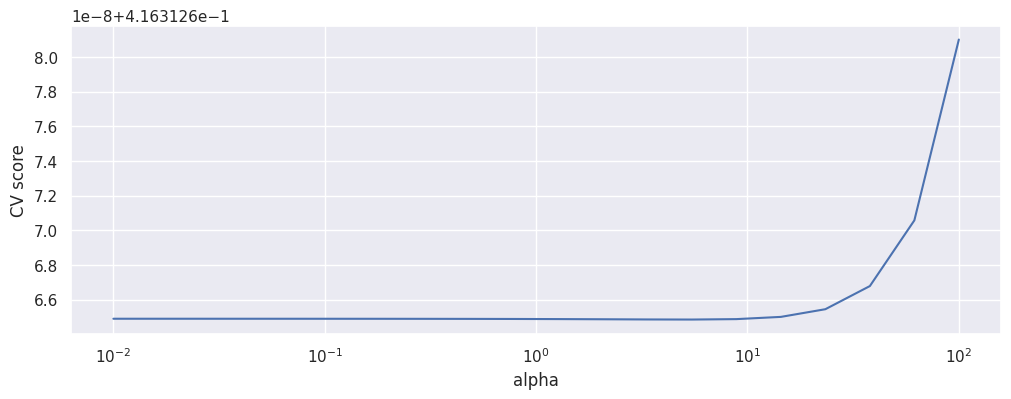

In [ ]:
from sklearn.model_selection import GridSearchCV

gs_ridge = GridSearchCV(pipeline_ridge, [params], scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, verbose=2)
gs_ridge.fit(X_train[train_features], y_train)

best_alpha_ridge = gs_ridge.best_params_["regression__alpha"]
print("Best alpha (Ridge) = %.4f" % best_alpha_ridge)

plt.plot(params['regression__alpha'], -gs_ridge.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV score (RMSE)");

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best alpha (Ridge) = 5.4556


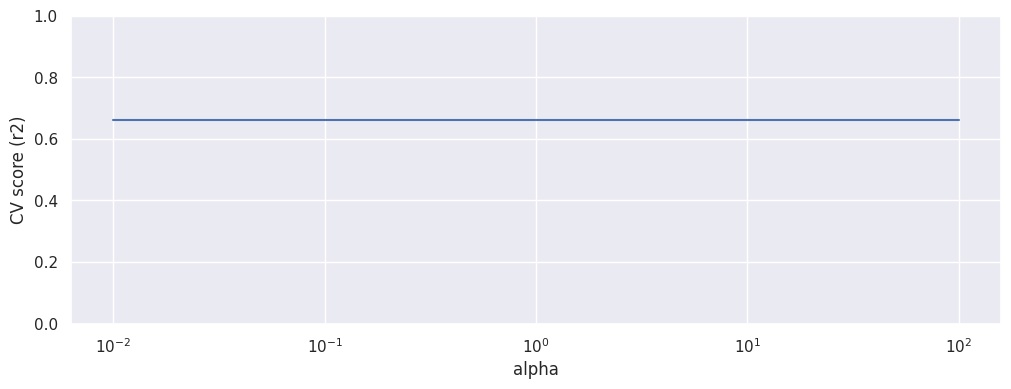

In [ ]:
gs_ridge = GridSearchCV(pipeline_ridge, [params], scoring="r2", cv=5, n_jobs=-1, verbose=2)
gs_ridge.fit(X_train[train_features], y_train)

best_alpha_ridge = gs_ridge.best_params_["regression__alpha"]
print("Best alpha (Ridge) = %.4f" % best_alpha_ridge)

plt.plot(params['regression__alpha'], gs_ridge.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV score (r2)")
plt.ylim(0, 1)
plt.show()

In [ ]:
gs_ridge.cv_results_["mean_test_score"]

array([0.66030226, 0.66030226, 0.66030226, 0.66030226, 0.66030226,
       0.66030226, 0.66030226, 0.66030226, 0.66030226, 0.66030226,
       0.66030226, 0.66030226, 0.66030226, 0.66030226, 0.66030226,
       0.66030226, 0.66030226, 0.66030226, 0.66030225, 0.66030224])

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best alpha (Lasso) = 0.0100


Text(0, 0.5, 'CV score')

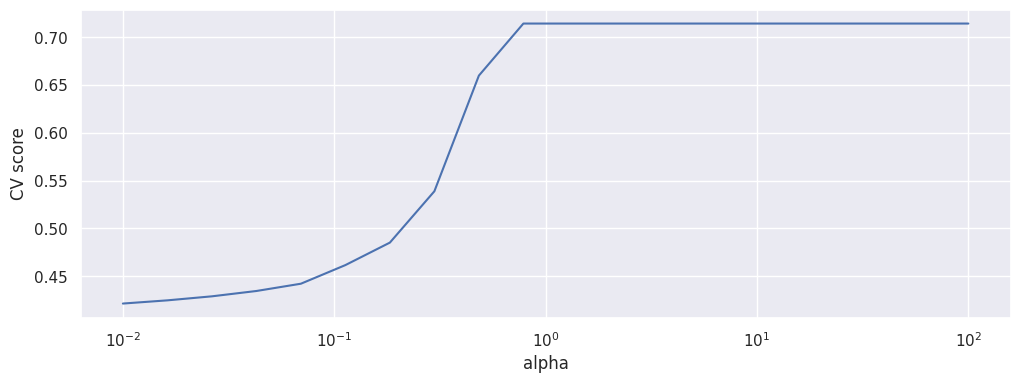

In [ ]:
gs_lasso = GridSearchCV(pipeline_lasso, [params], scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, verbose=2)
gs_lasso.fit(X_train[train_features], y_train)

best_alpha_lasso = gs_lasso.best_params_["regression__alpha"]
print("Best alpha (Lasso) = %.4f" % best_alpha_lasso)

plt.plot(params['regression__alpha'], -gs_lasso.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV score")
plt.show()

In [ ]:
gs_lasso = GridSearchCV(pipeline_ridge, [params], scoring="r2", cv=5, n_jobs=-1, verbose=2)
gs_lasso.fit(X_train[train_features], y_train)

best_alpha_lasso = gs_lasso.best_params_["regression__alpha"]
print("Best alpha (Lasso) = %.4f" % best_alpha_lasso)

plt.plot(params['regression__alpha'], gs_lasso.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV score (r2)")
plt.set_ylim(0, 1)
plt.show()